# Classical baselines for EuroSAT land-cover classification

**Question.** Before a quantum classifier for satellite images can be called useful, it has to beat a fair classical baseline. How high is that bar on EuroSAT, the Sentinel-2 dataset used in ESA Φ-lab's hybrid quantum CNN work?

Three baselines, one fixed data split:

1. **My CNN, trained from scratch.** The CNN I built for CIFAR-10 in my deep learning course (RDFIA, Sorbonne), adapted to 64×64 Sentinel-2 patches and trained only on EuroSAT.
2. **Reference ceiling: pretrained ResNet-18.** A standard ImageNet-pretrained network fine-tuned on the same split, to show how far a from-scratch model is from the usual transfer-learning result (Helber et al. report 98.57% with a fine-tuned ResNet-50).
3. **Qubit-budget baselines.** Quantum classifiers usually see only a handful of features, one per qubit. Here each image is compressed to *k* = 4, 8 or 16 PCA features, and small classical models are trained on exactly those features. This is the fair comparison for a *k*-qubit classifier: same inputs, similar parameter count.

Run on Colab: **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all** (about 35 minutes).

In [1]:
import os, json, time, zipfile, urllib.request, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

# Settings. QUICK_TEST runs the whole notebook in a minute on fake data, to check the code.
QUICK_TEST = os.environ.get("QUICK_TEST") == "1"
SPLIT_SEED = 42                       # one fixed train/val/test split for every experiment
SEEDS = [0] if QUICK_TEST else [0, 1, 2]   # CNN repeated over 3 seeds: report mean and spread
EPOCHS = 2 if QUICK_TEST else 30
BATCH_SIZE = 128
QUBIT_BUDGETS = [4, 8, 16]
DATA_ROOT = "data"
OUT = "results"
os.makedirs(OUT, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Using cuda | torch 2.14.1+cu130 | torchvision 0.29.1+cu130


## 1. Data

EuroSAT RGB: 27,000 Sentinel-2 patches of 64×64 pixels, 10 land-cover classes (Helber et al., 2019). The cell tries torchvision first, then two mirrors of the same archive. All images are loaded once into memory as a uint8 tensor (about 330 MB), which makes training much faster than reading files every epoch.

In [2]:
MIRRORS = [
    "https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/EuroSAT.zip",
    "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip",
]

def find_class_root(root):
    # Folder whose subfolders are the 10 classes (AnnualCrop, Forest, ...)
    for d, subdirs, _ in os.walk(root):
        if "AnnualCrop" in subdirs and "Forest" in subdirs:
            return d
    return None

def load_eurosat(root=DATA_ROOT):
    if QUICK_TEST:   # fake data with the same shape, only to test the code
        g = torch.Generator().manual_seed(0)
        X = torch.randint(0, 256, (1000, 3, 64, 64), dtype=torch.uint8, generator=g)
        y = torch.arange(1000) % 10
        return X, y, [f"class{i}" for i in range(10)]
    ds = None
    try:
        ds = torchvision.datasets.EuroSAT(root, download=True)
    except Exception as e:
        print("torchvision download failed:", e)
        if find_class_root(root) is None:
            for url in MIRRORS:
                try:
                    os.makedirs(root, exist_ok=True)
                    zpath = os.path.join(root, "eurosat.zip")
                    print("Downloading", url); urllib.request.urlretrieve(url, zpath)
                    zipfile.ZipFile(zpath).extractall(root); break
                except Exception as e2:
                    print("Mirror failed:", e2)
        ds = torchvision.datasets.ImageFolder(find_class_root(root))
    X = torch.empty((len(ds), 3, 64, 64), dtype=torch.uint8)
    y = torch.empty(len(ds), dtype=torch.long)
    for i in range(len(ds)):
        img, label = ds[i]
        X[i] = TF.pil_to_tensor(img.convert("RGB"))
        y[i] = label
    return X, y, ds.classes

t0 = time.time()
X, y, CLASSES = load_eurosat()
print(f"{len(X):,} images, {len(CLASSES)} classes, loaded in {time.time() - t0:.0f}s")
print(dict(zip(CLASSES, torch.bincount(y).tolist())))

100%|██████████| 94.3M/94.3M [00:00<00:00, 137MB/s]


27,000 images, 10 classes, loaded in 18s
{'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000}


## 2. One fixed split: 80% train, 10% validation, 10% test

Stratified, so every class keeps its share in each part. The validation set chooses the best epoch; the test set is used once per model, at the end.

In [3]:
idx = np.arange(len(y))
idx_train, idx_rest = train_test_split(idx, test_size=0.2, stratify=y.numpy(), random_state=SPLIT_SEED)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.5, stratify=y.numpy()[idx_rest], random_state=SPLIT_SEED)
print(len(idx_train), "train |", len(idx_val), "val |", len(idx_test), "test")
json.dump({"train": idx_train.tolist(), "val": idx_val.tolist(), "test": idx_test.tolist()},
          open(f"{OUT}/split_indices.json", "w"))

# Per-channel mean and std from the TRAINING images only, then applied to all three sets
Xf = X.float() / 255
MEAN = Xf[idx_train].mean(dim=(0, 2, 3)); STD = Xf[idx_train].std(dim=(0, 2, 3))
Xn = (Xf - MEAN[None, :, None, None]) / STD[None, :, None, None]
del Xf
print("mean", MEAN.numpy().round(3), "std", STD.numpy().round(3))

21600 train | 2700 val | 2700 test
mean [0.344 0.38  0.408] std [0.203 0.137 0.115]


## 3. Baseline 1: full-image CNN

The architecture is the CIFAR-10 network from my RDFIA lab (three 5×5 conv layers with 32, 64, 64 filters, batch norm, max-pooling, a 1000-unit layer with dropout 0.5), adapted to 64×64 inputs. Same recipe as in the lab: SGD with learning rate 0.1 and exponential decay (γ = 0.95).

**Augmentation.** In the lab, horizontal flips suited CIFAR-10 but vertical flips would not (a car upside down is not a car). Satellite patches have no "up", so here every flip and every 90° rotation is valid: 8 versions of each image.

In [4]:
class ConvNet(nn.Module):
    def __init__(self, n_classes=10, dropout=0.5):
        super().__init__()
        def block(c_in, c_out):
            return [nn.Conv2d(c_in, c_out, 5, padding=2), nn.BatchNorm2d(c_out), nn.ReLU(),
                    nn.MaxPool2d(2, 2, ceil_mode=True)]
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 64))   # 64 -> 32 -> 16 -> 8
        self.classifier = nn.Sequential(nn.Linear(64 * 8 * 8, 1000), nn.ReLU(), nn.Dropout(dropout),
                                        nn.Linear(1000, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

def augment(x):
    # Random horizontal flip, vertical flip and 90-degree rotation, drawn per image
    b = x.size(0)
    hf = torch.rand(b, device=x.device) < 0.5
    vf = torch.rand(b, device=x.device) < 0.5
    x = torch.where(hf[:, None, None, None], x.flip(3), x)
    x = torch.where(vf[:, None, None, None], x.flip(2), x)
    rot = torch.rand(b, device=x.device) < 0.5
    return torch.where(rot[:, None, None, None], x.transpose(2, 3), x)   # transpose + flips covers all 8 symmetries

def batches(ids, shuffle):
    ids = np.random.permutation(ids) if shuffle else ids
    for i in range(0, len(ids), BATCH_SIZE):
        j = ids[i:i + BATCH_SIZE]
        yield Xn[j].to(device, non_blocking=True), y[j].to(device, non_blocking=True)

def evaluate(model, ids):
    model.eval(); preds = []
    with torch.no_grad():
        for xb, _ in batches(ids, shuffle=False):
            preds.append(model(xb).argmax(1).cpu())
    preds = torch.cat(preds)
    return (preds == y[ids]).float().mean().item() * 100, preds

def train_cnn(seed):
    set_seed(seed)
    model = ConvNet().to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.95)
    best_val, best_state, history = -1, None, []
    for ep in range(EPOCHS):
        model.train(); t0 = time.time(); correct = n = 0
        for xb, yb in batches(idx_train, shuffle=True):
            out = model(augment(xb)); loss = F.cross_entropy(out, yb)
            opt.zero_grad(); loss.backward(); opt.step()
            correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        sched.step()
        val_acc, _ = evaluate(model, idx_val)
        history.append({"epoch": ep + 1, "train_acc": 100 * correct / n, "val_acc": val_acc})
        if val_acc > best_val:
            best_val, best_state = val_acc, {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"seed {seed} epoch {ep + 1:2d}/{EPOCHS} ({time.time() - t0:.0f}s)  train {100 * correct / n:5.2f}%  val {val_acc:5.2f}%")
    model.load_state_dict(best_state)
    test_acc, preds = evaluate(model, idx_test)
    return model, test_acc, best_val, preds, history

n_params = sum(p.numel() for p in ConvNet().parameters())
print(f"{n_params:,} trainable parameters")

4,263,490 trainable parameters


In [5]:
cnn_runs = []
for s in SEEDS:
    model, test_acc, val_acc, preds, history = train_cnn(s)
    cnn_runs.append({"seed": s, "test_acc": test_acc, "best_val_acc": val_acc, "history": history})
    print(f"==> seed {s}: test accuracy {test_acc:.2f}% (best validation {val_acc:.2f}%)\n")

accs = np.array([r["test_acc"] for r in cnn_runs])
print(f"CNN test accuracy over {len(accs)} seeds: {accs.mean():.2f}% ± {accs.std(ddof=1) if len(accs) > 1 else 0:.2f}")

seed 0 epoch  1/30 (8s)  train 48.77%  val 41.41%
seed 0 epoch  2/30 (5s)  train 66.28%  val 67.44%
seed 0 epoch  3/30 (5s)  train 72.22%  val 55.96%
seed 0 epoch  4/30 (6s)  train 75.96%  val 78.81%
seed 0 epoch  5/30 (5s)  train 78.33%  val 65.26%
seed 0 epoch  6/30 (5s)  train 80.60%  val 67.93%
seed 0 epoch  7/30 (5s)  train 81.78%  val 74.26%
seed 0 epoch  8/30 (6s)  train 83.38%  val 78.41%
seed 0 epoch  9/30 (5s)  train 84.69%  val 74.67%
seed 0 epoch 10/30 (6s)  train 85.66%  val 80.19%
seed 0 epoch 11/30 (5s)  train 86.58%  val 85.04%
seed 0 epoch 12/30 (6s)  train 87.52%  val 84.26%
seed 0 epoch 13/30 (6s)  train 88.95%  val 80.59%
seed 0 epoch 14/30 (5s)  train 89.19%  val 86.41%
seed 0 epoch 15/30 (6s)  train 90.25%  val 90.44%
seed 0 epoch 16/30 (6s)  train 90.54%  val 90.74%
seed 0 epoch 17/30 (6s)  train 91.21%  val 91.41%
seed 0 epoch 18/30 (6s)  train 91.67%  val 83.44%
seed 0 epoch 19/30 (6s)  train 91.98%  val 92.30%
seed 0 epoch 20/30 (6s)  train 92.34%  val 91.70%


PermanentCrop           88.40%
HerbaceousVegetation    89.33%
Highway                 91.60%
AnnualCrop              92.00%
River                   94.80%
Pasture                 97.00%
Residential             98.00%
SeaLake                 98.33%
Forest                  98.67%
Industrial              99.20%


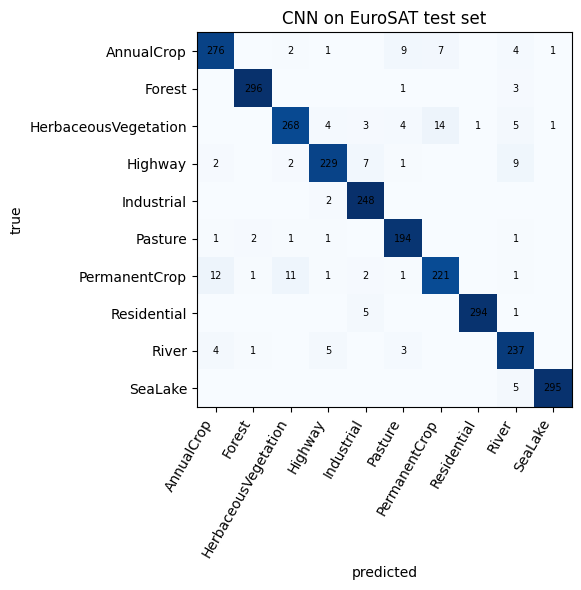

In [6]:
# Per-class accuracy and confusion matrix of the last seed's model
cm = confusion_matrix(y[idx_test].numpy(), preds.numpy(), labels=range(len(CLASSES)))
per_class = {c: round(100 * cm[i, i] / cm[i].sum(), 2) for i, c in enumerate(CLASSES)}
for c, a in sorted(per_class.items(), key=lambda t: t[1]):
    print(f"{c:22s} {a:6.2f}%")

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=60, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("CNN on EuroSAT test set")
plt.tight_layout(); plt.savefig(f"{OUT}/cnn_confusion_matrix.png", dpi=150); plt.show()

## 4. Reference ceiling: ImageNet-pretrained ResNet-18, fine-tuned

Unlike my CNN, this network starts from weights learned on 1.2 million ImageNet photos. Images are scaled from 64×64 to 224×224, the size ResNet was trained on, and normalised with ImageNet statistics. Same split, same augmentation, best epoch chosen on validation, test used once. One seed only, to keep the run short.

In [7]:
RESNET_EPOCHS = 1 if QUICK_TEST else 10
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device)[None, :, None, None]
IMNET_STD = torch.tensor([0.229, 0.224, 0.225], device=device)[None, :, None, None]

def resnet_batches(ids, shuffle, train):
    ids = np.random.permutation(ids) if shuffle else ids
    for i in range(0, len(ids), BATCH_SIZE):
        j = ids[i:i + BATCH_SIZE]
        xb = X[j].to(device).float() / 255
        if train: xb = augment(xb)
        xb = F.interpolate(xb, size=224, mode="bilinear", align_corners=False)
        yield (xb - IMNET_MEAN) / IMNET_STD, y[j].to(device)

def resnet_eval(model, ids):
    model.eval(); preds = []
    with torch.no_grad(), torch.autocast(device_type="cuda", enabled=(device == "cuda")):
        for xb, _ in resnet_batches(ids, shuffle=False, train=False):
            preds.append(model(xb).argmax(1).cpu())
    preds = torch.cat(preds)
    return (preds == y[ids]).float().mean().item() * 100

set_seed(0)
weights = None if QUICK_TEST else torchvision.models.ResNet18_Weights.IMAGENET1K_V1   # QUICK_TEST: no download
resnet = torchvision.models.resnet18(weights=weights)
resnet.fc = nn.Linear(resnet.fc.in_features, len(CLASSES))    # new 10-class output layer
resnet = resnet.to(device)
resnet_params = sum(p.numel() for p in resnet.parameters())
opt = torch.optim.SGD(resnet.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=RESNET_EPOCHS)
scaler = torch.amp.GradScaler(enabled=(device == "cuda"))
best_val, best_state, resnet_history = -1, None, []
for ep in range(RESNET_EPOCHS):
    resnet.train(); t0 = time.time()
    for xb, yb in resnet_batches(idx_train, shuffle=True, train=True):
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            loss = F.cross_entropy(resnet(xb), yb)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    sched.step()
    val_acc = resnet_eval(resnet, idx_val); resnet_history.append({"epoch": ep + 1, "val_acc": val_acc})
    if val_acc > best_val:
        best_val, best_state = val_acc, {k: v.detach().clone() for k, v in resnet.state_dict().items()}
    print(f"ResNet-18 epoch {ep + 1:2d}/{RESNET_EPOCHS} ({time.time() - t0:.0f}s)  val {val_acc:5.2f}%")
resnet.load_state_dict(best_state)
resnet_test = resnet_eval(resnet, idx_test)
print(f"\nPretrained ResNet-18 ({resnet_params:,} parameters): test accuracy {resnet_test:.2f}%")
print(f"My CNN from scratch ({n_params:,} parameters): {accs.mean():.2f}% mean over {len(accs)} seeds")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


ResNet-18 epoch  1/10 (33s)  val 95.96%
ResNet-18 epoch  2/10 (33s)  val 96.70%
ResNet-18 epoch  3/10 (33s)  val 97.37%
ResNet-18 epoch  4/10 (33s)  val 97.70%
ResNet-18 epoch  5/10 (33s)  val 98.48%
ResNet-18 epoch  6/10 (33s)  val 98.59%
ResNet-18 epoch  7/10 (33s)  val 98.56%
ResNet-18 epoch  8/10 (33s)  val 98.81%
ResNet-18 epoch  9/10 (33s)  val 98.78%
ResNet-18 epoch 10/10 (33s)  val 98.67%

Pretrained ResNet-18 (11,181,642 parameters): test accuracy 98.59%
My CNN from scratch (4,263,490 parameters): 94.27% mean over 3 seeds


## 5. Qubit-budget baselines: what *k* features buy a classical model

A *k*-qubit classifier typically sees *k* numbers per image, for example with angle encoding. To give a classical model the same input, each image is averaged down to 32×32, flattened (3,072 values) and projected onto its first *k* principal components, fitted on the training set only. Two classical models are trained on those *k* features:

- **logistic regression**: 10·(*k*+1) parameters, a linear model;
- **small MLP** (one hidden layer of 16 units): a non-linear model with a few hundred parameters, the size of a small variational circuit.

If a *k*-qubit quantum classifier cannot beat these numbers, its advantage on this task is not shown.

In [8]:
X32 = F.avg_pool2d(Xn, 2).flatten(1).numpy()          # 64x64 -> 32x32, 3,072 features
Xtr, Xva, Xte = X32[idx_train], X32[idx_val], X32[idx_test]
ytr, yva, yte = y[idx_train].numpy(), y[idx_val].numpy(), y[idx_test].numpy()

budget_rows = []
for k in QUBIT_BUDGETS:
    pca = PCA(n_components=k, random_state=SPLIT_SEED).fit(Xtr)
    Ztr, Zva, Zte = pca.transform(Xtr), pca.transform(Xva), pca.transform(Xte)
    scale = Ztr.std(0); Ztr, Zva, Zte = Ztr / scale, Zva / scale, Zte / scale
    logreg = LogisticRegression(max_iter=2000).fit(Ztr, ytr)
    mlp = MLPClassifier(hidden_layer_sizes=(16,), max_iter=500, early_stopping=True, random_state=0).fit(Ztr, ytr)
    row = {
        "k": k,
        "pca_variance_kept": round(float(100 * pca.explained_variance_ratio_.sum()), 2),
        "logreg_params": 10 * (k + 1), "logreg_test_acc": round(100 * logreg.score(Zte, yte), 2),
        "mlp_params": k * 16 + 16 + 16 * 10 + 10, "mlp_test_acc": round(100 * mlp.score(Zte, yte), 2),
    }
    budget_rows.append(row); print(row)

{'k': 4, 'pca_variance_kept': 72.62, 'logreg_params': 50, 'logreg_test_acc': 38.11, 'mlp_params': 250, 'mlp_test_acc': 54.37}
{'k': 8, 'pca_variance_kept': 77.08, 'logreg_params': 90, 'logreg_test_acc': 39.48, 'mlp_params': 314, 'mlp_test_acc': 57.22}
{'k': 16, 'pca_variance_kept': 81.4, 'logreg_params': 170, 'logreg_test_acc': 43.26, 'mlp_params': 442, 'mlp_test_acc': 63.85}


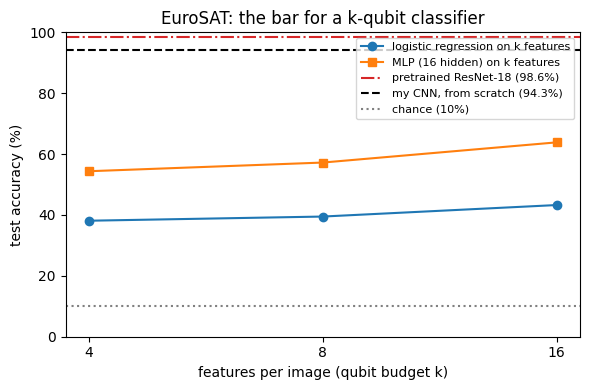

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ks = [r["k"] for r in budget_rows]
ax.plot(ks, [r["logreg_test_acc"] for r in budget_rows], "o-", label="logistic regression on k features")
ax.plot(ks, [r["mlp_test_acc"] for r in budget_rows], "s-", label="MLP (16 hidden) on k features")
ax.axhline(resnet_test, color="tab:red", ls="-.", label=f"pretrained ResNet-18 ({resnet_test:.1f}%)")
ax.axhline(accs.mean(), color="k", ls="--", label=f"my CNN, from scratch ({accs.mean():.1f}%)")
ax.axhline(10, color="grey", ls=":", label="chance (10%)")
ax.set_xscale("log", base=2); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_xlabel("features per image (qubit budget k)"); ax.set_ylabel("test accuracy (%)")
ax.set_ylim(0, 100); ax.legend(fontsize=8); ax.set_title("EuroSAT: the bar for a k-qubit classifier")
plt.tight_layout(); plt.savefig(f"{OUT}/qubit_budget_baselines.png", dpi=150); plt.show()

## 6. Save the results

Everything needed for the README is written to `results/results.json`.

In [10]:
results = {
    "dataset": "EuroSAT RGB (Sentinel-2), 27,000 images, 10 classes" if not QUICK_TEST else "FAKE DATA (quick test)",
    "split": {"seed": SPLIT_SEED, "train": len(idx_train), "val": len(idx_val), "test": len(idx_test)},
    "cnn": {"params": n_params, "epochs": EPOCHS, "seeds": SEEDS,
            "test_acc_mean": round(float(accs.mean()), 2),
            "test_acc_std": round(float(accs.std(ddof=1)), 2) if len(accs) > 1 else 0.0,
            "runs": cnn_runs, "per_class_test_acc_last_seed": per_class},
    "resnet18_pretrained": {"params": resnet_params, "epochs": RESNET_EPOCHS, "seed": 0,
                            "best_val_acc": round(best_val, 2), "test_acc": round(resnet_test, 2),
                            "history": resnet_history},
    "qubit_budget_baselines": budget_rows,
    "device": device, "torch": torch.__version__,
}
json.dump(results, open(f"{OUT}/results.json", "w"), indent=2)
print(json.dumps({k: v for k, v in results.items() if k != "cnn"}, indent=2))
print("My CNN:", results["cnn"]["test_acc_mean"], "+/-", results["cnn"]["test_acc_std"], "%")
print("Pretrained ResNet-18:", results["resnet18_pretrained"]["test_acc"], "%")

{
  "dataset": "EuroSAT RGB (Sentinel-2), 27,000 images, 10 classes",
  "split": {
    "seed": 42,
    "train": 21600,
    "val": 2700,
    "test": 2700
  },
  "resnet18_pretrained": {
    "params": 11181642,
    "epochs": 10,
    "seed": 0,
    "best_val_acc": 98.81,
    "test_acc": 98.59,
    "history": [
      {
        "epoch": 1,
        "val_acc": 95.96296548843384
      },
      {
        "epoch": 2,
        "val_acc": 96.70370221138
      },
      {
        "epoch": 3,
        "val_acc": 97.3703682422638
      },
      {
        "epoch": 4,
        "val_acc": 97.70370125770569
      },
      {
        "epoch": 5,
        "val_acc": 98.48148226737976
      },
      {
        "epoch": 6,
        "val_acc": 98.59259128570557
      },
      {
        "epoch": 7,
        "val_acc": 98.55555295944214
      },
      {
        "epoch": 8,
        "val_acc": 98.81481528282166
      },
      {
        "epoch": 9,
        "val_acc": 98.77777695655823
      },
      {
        "epoch": 10,
